# Part 1: Filters, Edges and Seam Finding

In [1]:
import os, time, sys
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import cv2
from scipy.signal import convolve2d #for comparison pt 1.1
STARTER = Path("starter_pack")
sys.path.insert(0, str(STARTER / "code"))
from utils import load_image, show

IMG_ROOT = STARTER / "images"

from convolution import conv2d_loop, conv2d_vec, conv2d_sep, gaussian_kernel, separate
from filters_helpers import (Dx, Dy, to_gray, finite_diff, gradient_magnitude,dog_filters, dog_diff, signed_to_display)

os.makedirs("figs", exist_ok=True)  


def load(path, gray=False, max_side=1000):
    im = load_image(path, gray=gray)
    s = max_side/max(im.shape[:2])    #shrink keeping aspect ratio
    if s < 1:   
        im = cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return im

#save helper -lel report
def row(imgs, titles, name=None, size=4):
    if name is None:
        return show(*imgs, titles=titles, size=size)
    real_show = plt.show
    def show_and_save(*a, **k):
        plt.savefig(f"figs/{name}.png", dpi=150, bbox_inches="tight")
        real_show(*a, **k)
    plt.show = show_and_save
    try:
        show(*imgs, titles=titles, size=size)
    finally:
        plt.show = real_show

## 1.1 Convolution from scratch

In [2]:
#checking all 3 randoms and scipy, seperable / non seperable
rng = np.random.default_rng(0)
for trial in range(50):
    img = rng.random((rng.integers(5, 25), rng.integers(5, 25)))
    kh, kw = rng.choice([1, 3, 5, 7, 9]), rng.choice([1, 3, 5, 7, 9])
    for k in (rng.random((kh, kw)), np.outer(rng.random(kh), rng.random(kw))):  # non-separable, separable
        ref = convolve2d(img, k, mode="same")   #scipy.signal function
        for f in (conv2d_loop, conv2d_vec, conv2d_sep):
            assert np.allclose(f(img, k), ref, atol=1e-10), (f.__name__, k.shape)
print("loop, vectorized and separable all match scipy.signal.convolve2d(mode='same')")

loop, vectorized and separable all match scipy.signal.convolve2d(mode='same')


  size   loop (s)   vectorized (s)   separable (s)
  3x3       0.190           0.0005          0.0009
  5x5       0.475           0.0013          0.0006
  7x7       0.884           0.0022          0.0008
  9x9       1.507           0.0044          0.0012
 11x11      2.090           0.0050          0.0010
 13x13      2.979           0.0076          0.0017
 15x15      3.992           0.0097          0.0014
 17x17      5.006           0.0133          0.0017
 19x19      6.224           0.0166          0.0018
 21x21      7.211           0.0200          0.0018
 23x23      8.819           0.0220          0.0018
 25x25     10.024           0.0272          0.0022
 27x27     11.801           0.0304          0.0021
 29x29     13.393           0.0340          0.0025
 31x31     15.132           0.0389          0.0024


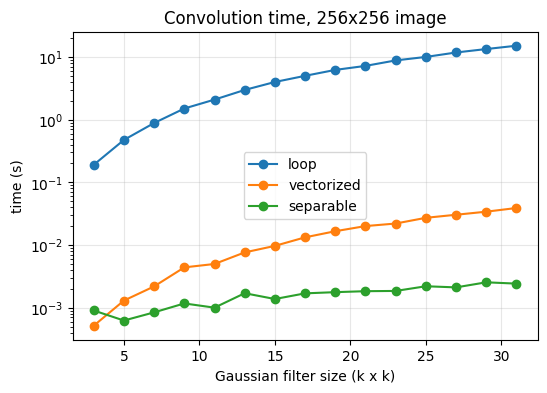

In [3]:
img256 = np.random.default_rng(1).random((256, 256))
sizes = list(range(3, 32, 2))
LOOP_SIZES = sizes

def best_time(f, img, k, reps):
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); f(img, k); ts.append(time.perf_counter() - t)
    return min(ts)

T = {"loop": {}, "vectorized": {}, "separable": {}}
for n in sizes:
    k = gaussian_kernel(n, sigma=n / 6)
    assert separate(k) is not None
    if n in LOOP_SIZES: T["loop"][n] = best_time(conv2d_loop, img256, k, 1)
    T["vectorized"][n] = best_time(conv2d_vec, img256, k, 5)
    T["separable"][n] = best_time(conv2d_sep, img256, k, 5)

print(f"{'size':>6} {'loop (s)':>10} {'vectorized (s)':>16} {'separable (s)':>15}")
for n in sizes:
    l = f"{T['loop'][n]:.3f}" if n in T["loop"] else "-"
    print(f"{n:>3}x{n:<2} {l:>10} {T['vectorized'][n]:>16.4f} {T['separable'][n]:>15.4f}")

plt.figure(figsize=(6, 4))
for name, d in T.items():
    plt.semilogy(list(d), list(d.values()), "o-", label=name)
plt.xlabel("Gaussian filter size (k x k)"); plt.ylabel("time (s)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Convolution time, 256x256 image")
plt.savefig("figs/timing.png", dpi=150, bbox_inches="tight"); plt.show()

### Time difference
- Loop: about H·W·k² Python-level multiply-adds; the interpreter overhead per operation dominates, so it is orders of magnitude slower and grows as k².  
- Vectorized: only k² iterations, each a whole-image NumPy operation running in compiled code. Still O(H·W·k²) arithmetic, but with small per-element cost.  
- Separable: two 1D passes, 2k whole-image operations, so O(H·W·k): linear in k instead of quadratic. The gap to the vectorized version widens as the filter grows.  
- The SVD rank test costs almost nothing (k is small).

## 1.2 Finite difference operator

In [4]:
gray = load(IMG_ROOT / "part1_filters" / "cameraman.png", gray=True)
#print(gray.shape)

gx, gy = finite_diff(gray, pad_mode="constant")
gm = gradient_magnitude(gx, gy)

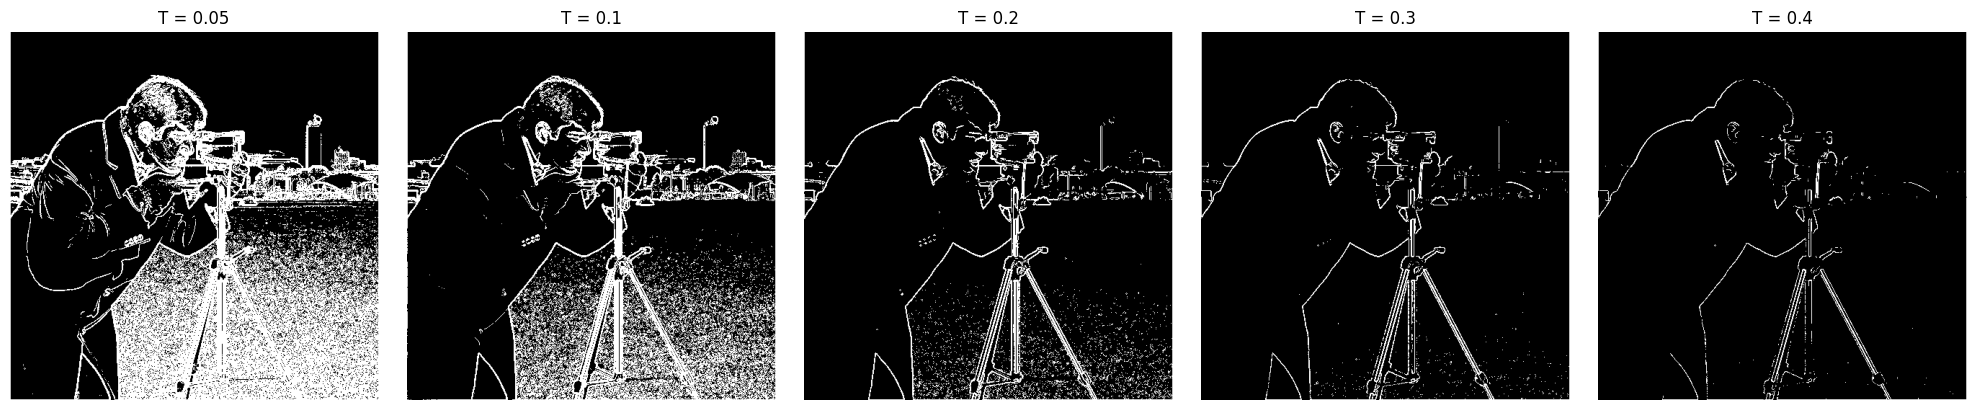

In [5]:
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for a, t in zip(ax, [0.05, 0.1, 0.2, 0.3, 0.4]):
    a.imshow(gm > t, cmap="gray"); a.set_title(f"T = {t}"); a.axis("off")
plt.tight_layout(); plt.show()

Low T (0.05): almost everything counts as an edge, so flat regions fill with noise speckle.  
High T (0.4): only the strongest edges survive, and real edges start to break up or vanish.
T = 0.2 is the lowest value that suppresses the noise in flat areas without losing the main contours. 

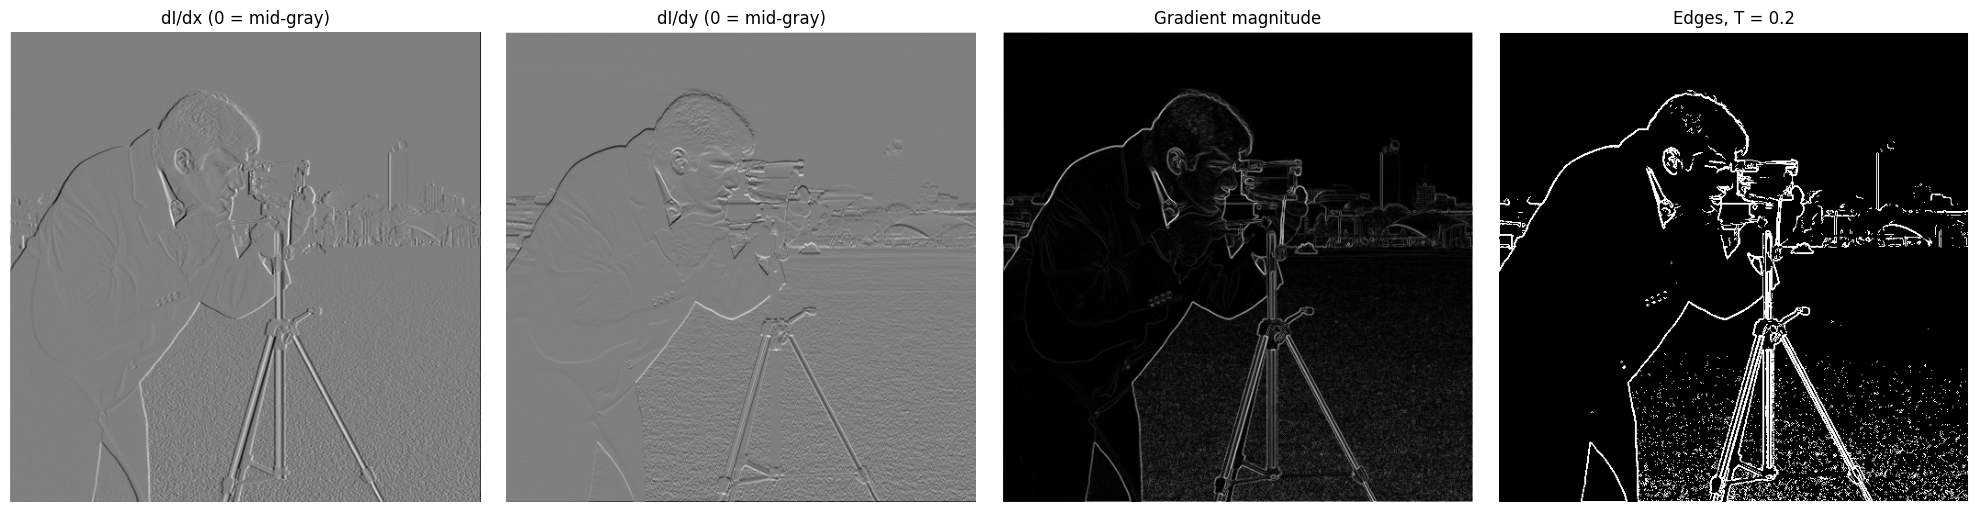

In [6]:
T = 0.2
edges12 = gm > T
row([signed_to_display(gx), signed_to_display(gy), gm / gm.max(), edges12.astype(float)],
    ["dI/dx (0 = mid-gray)", "dI/dy (0 = mid-gray)", "Gradient magnitude", f"Edges, T = {T}"], name="1_2_finite_diff", size=5)

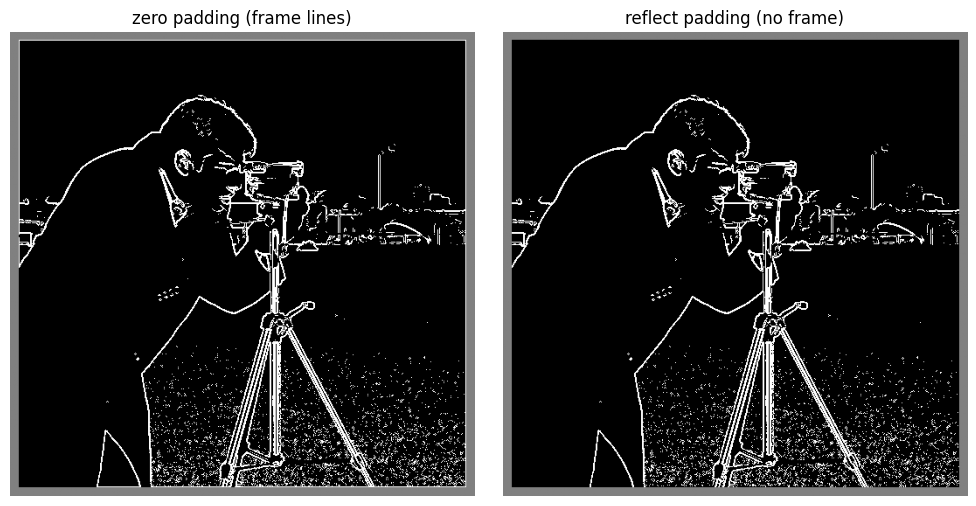

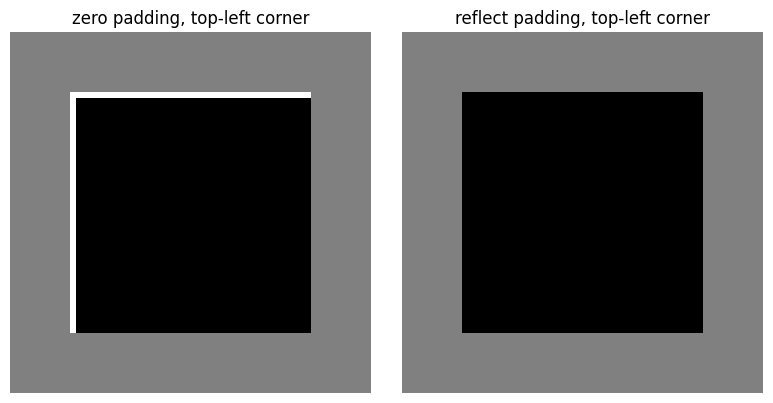

In [7]:
gx_r, gy_r = finite_diff(gray, pad_mode="reflect")
gm_r = gradient_magnitude(gx_r, gy_r)
def with_margin(e, m=10):
    return np.pad(e.astype(float), m, constant_values=0.5)   #gray frame around edge map - edge visibility

row([with_margin(gm > T), with_margin(gm_r > T)],
    ["zero padding (frame lines)", "reflect padding (no frame)"],
    name="1_2_frame", size=5)

row([with_margin((gm > T)[:40, :40]), with_margin((gm_r > T)[:40, :40])],   #enlarged version for visibility
    ["zero padding, top-left corner", "reflect padding, top-left corner"],
    name="1_2_corner", size=4)


Convolution fills frames with zeros (black). So at the first and last row and column, the derivative filter compares a real pixel with a fake black one, so its is therefore detected as an edge.

(670, 736) max gradient magnitude: 1.232


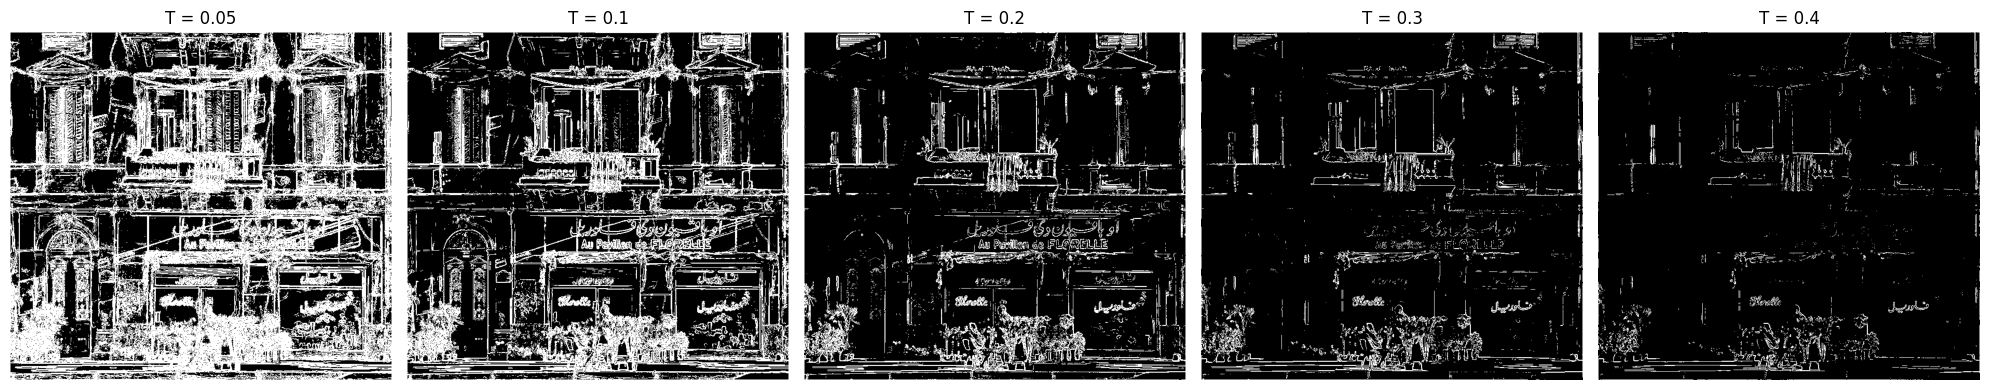

In [8]:
gray_f = load(IMG_ROOT / "part1_filters" / "facade.png", gray=True)
gx_f, gy_f = finite_diff(gray_f)
gm_f = gradient_magnitude(gx_f, gy_f)
print(gray_f.shape, "max gradient magnitude: %.3f" % gm_f.max())

fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for a, t in zip(ax, [0.05, 0.1, 0.2, 0.3, 0.4]):
    a.imshow(gm_f > t, cmap="gray"); a.set_title(f"T = {t}"); a.axis("off")
plt.tight_layout(); plt.show()

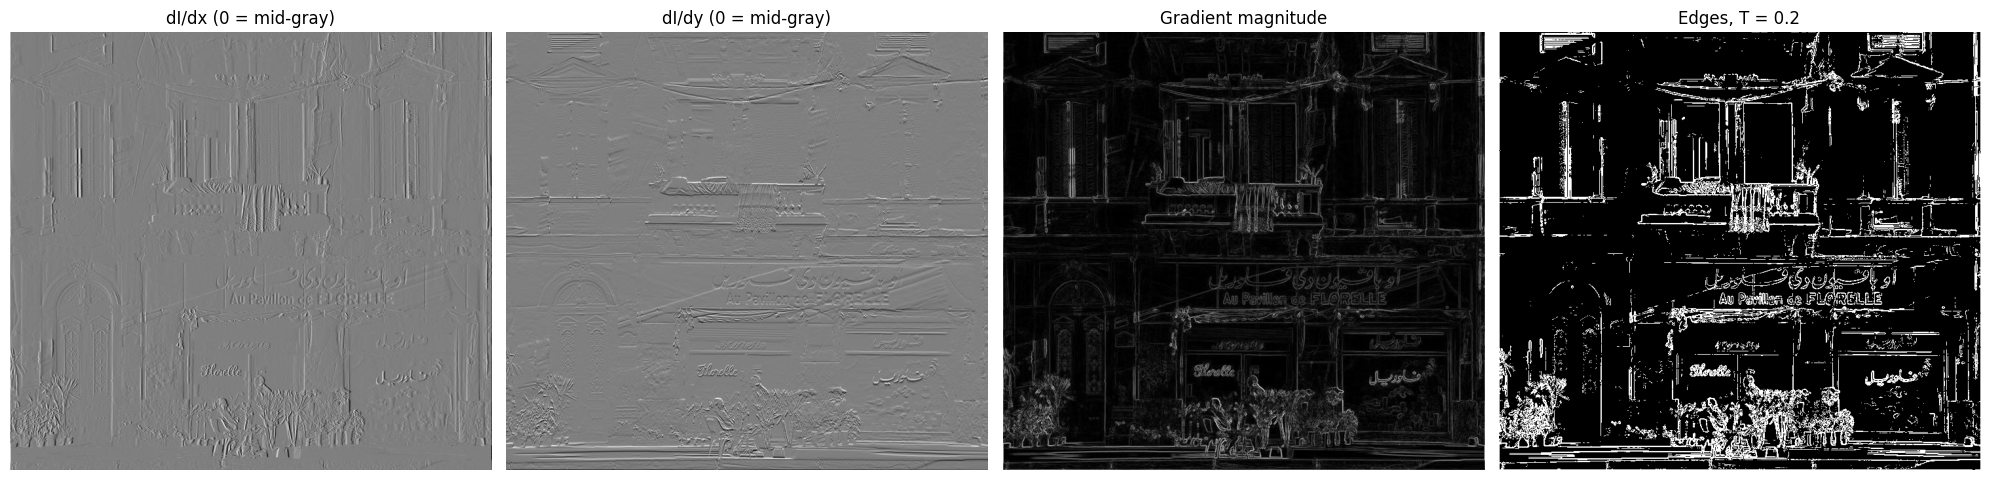

In [9]:
T2 = 0.2   
edges12_f = gm_f > T2
row([signed_to_display(gx_f), signed_to_display(gy_f), gm_f / gm_f.max(), edges12_f.astype(float)],
    ["dI/dx (0 = mid-gray)", "dI/dy (0 = mid-gray)", "Gradient magnitude", f"Edges, T = {T2}"],
    name="1_2_facade", size=5)

## 1.3 Derivative of Gaussian (DoG)

In [10]:
SIGMA = 2
SIZE = int(2*np.ceil(3 * SIGMA) + 1)
dogx, dogy = dog_filters(SIZE, SIGMA)
print("DoG kernels separable:", separate(dogx) is not None, separate(dogy) is not None)

dx_g, dy_g = dog_diff(gray, dogx, dogy, pad_mode="constant")
gm_dog = gradient_magnitude(dx_g, dy_g)

G = gaussian_kernel(SIZE, SIGMA)
two_step = conv2d_sep(conv2d_sep(gray, G), Dx)
m = SIZE
print("max diff vs blur-then-Dx (interior):", np.abs(two_step - dx_g)[m:-m, m:-m].max())

DoG kernels separable: True True
max diff vs blur-then-Dx (interior): 0.002089098152031732


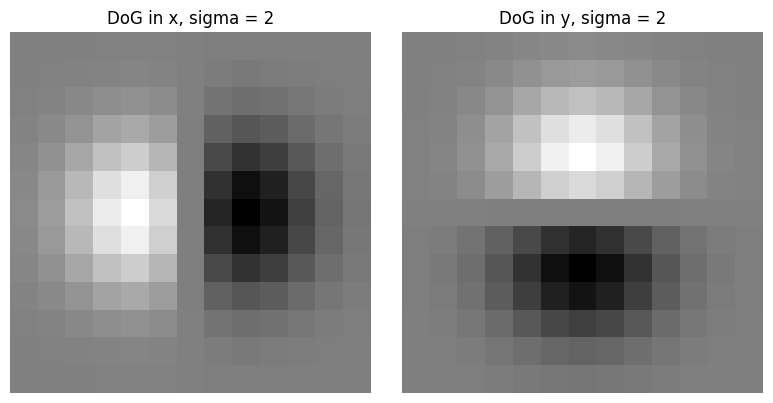

In [11]:
row([signed_to_display(dogx), signed_to_display(dogy)],
    [f"DoG in x, sigma = {SIGMA}", f"DoG in y, sigma = {SIGMA}"], name="1_3_filters", size=4)

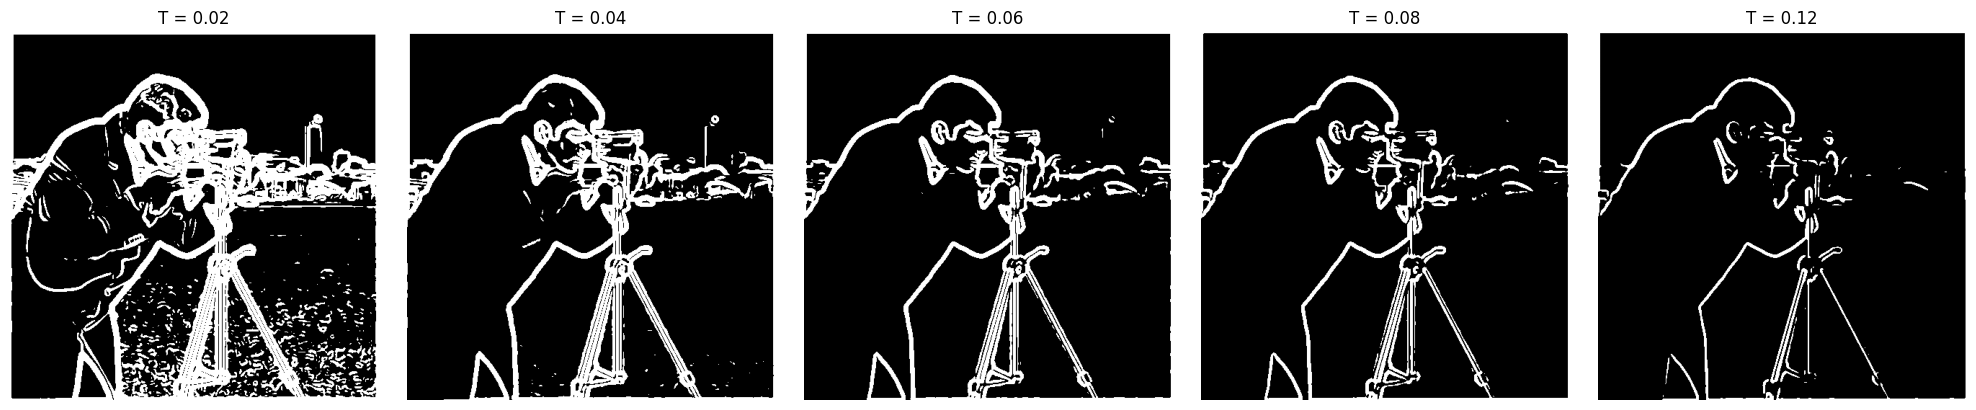

In [12]:
fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for a, t in zip(ax, [0.02, 0.04, 0.06, 0.08, 0.12]):
    a.imshow(gm_dog > t, cmap="gray"); a.set_title(f"T = {t}"); a.axis("off")
plt.tight_layout(); plt.show()

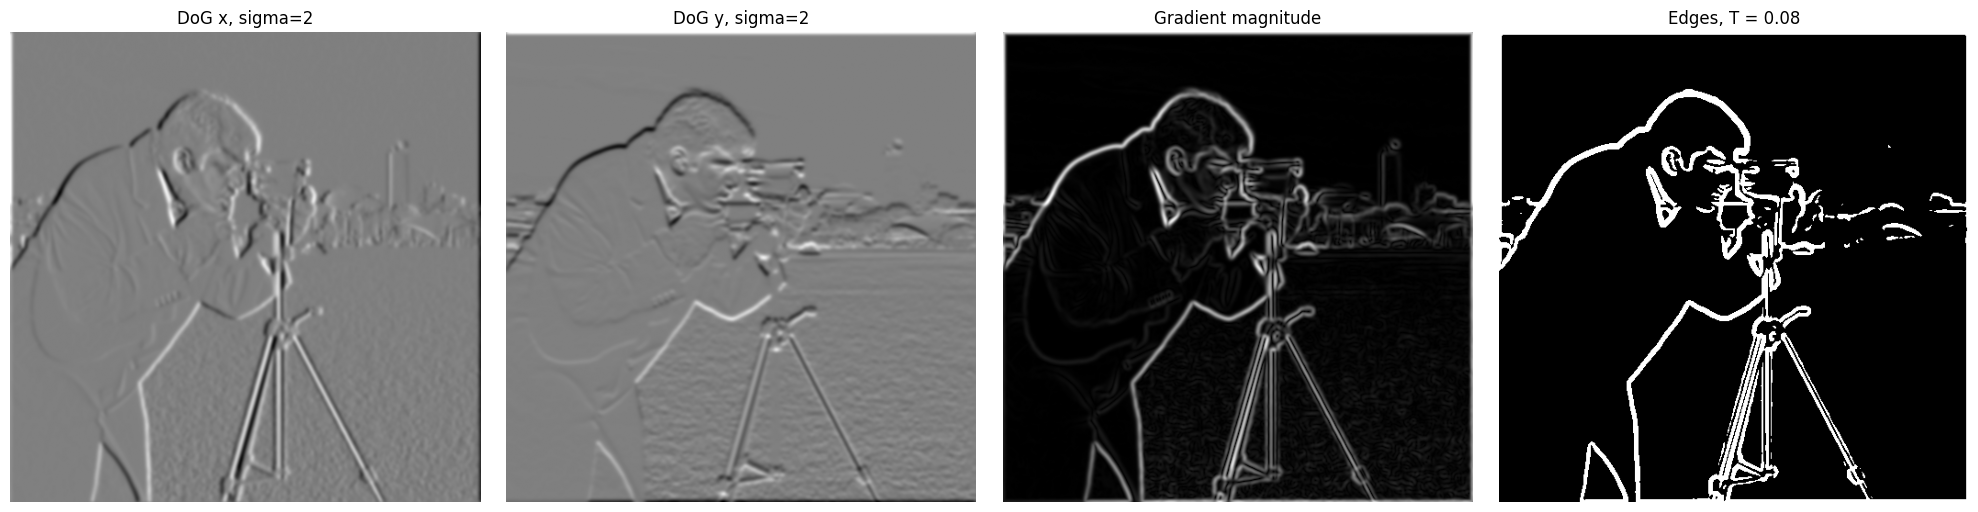

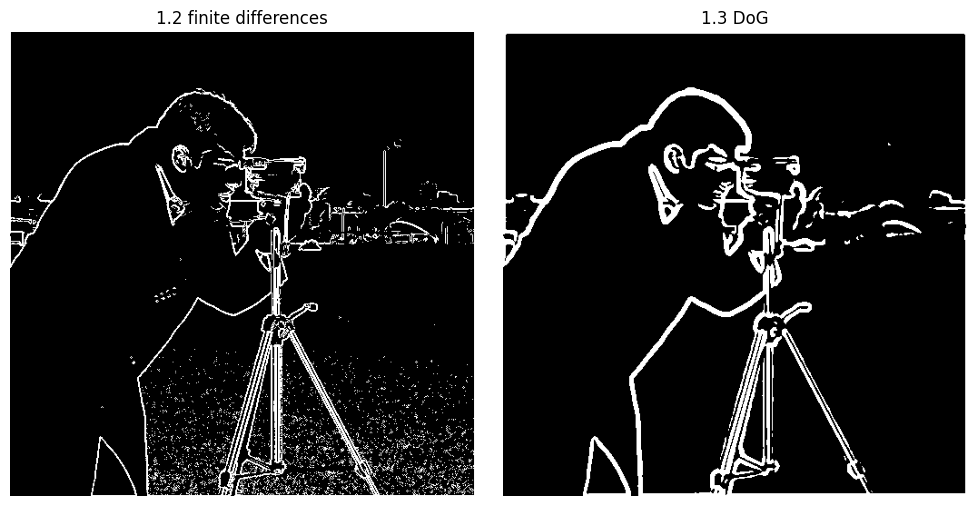

In [ ]:
T13 = 0.08
edges13 = gm_dog > T13
row([signed_to_display(dx_g), signed_to_display(dy_g), gm_dog / gm_dog.max(), edges13.astype(float)],
    [f"DoG x, sigma={SIGMA}", f"DoG y, sigma={SIGMA}", "Gradient magnitude", f"Edges, T = {T13}"],
    name="1_3_dog", size=5)
row([edges12.astype(float), edges13.astype(float)], ["1.2 finite differences", "1.3 DoG"],
    name="1_3_compare", size=5)

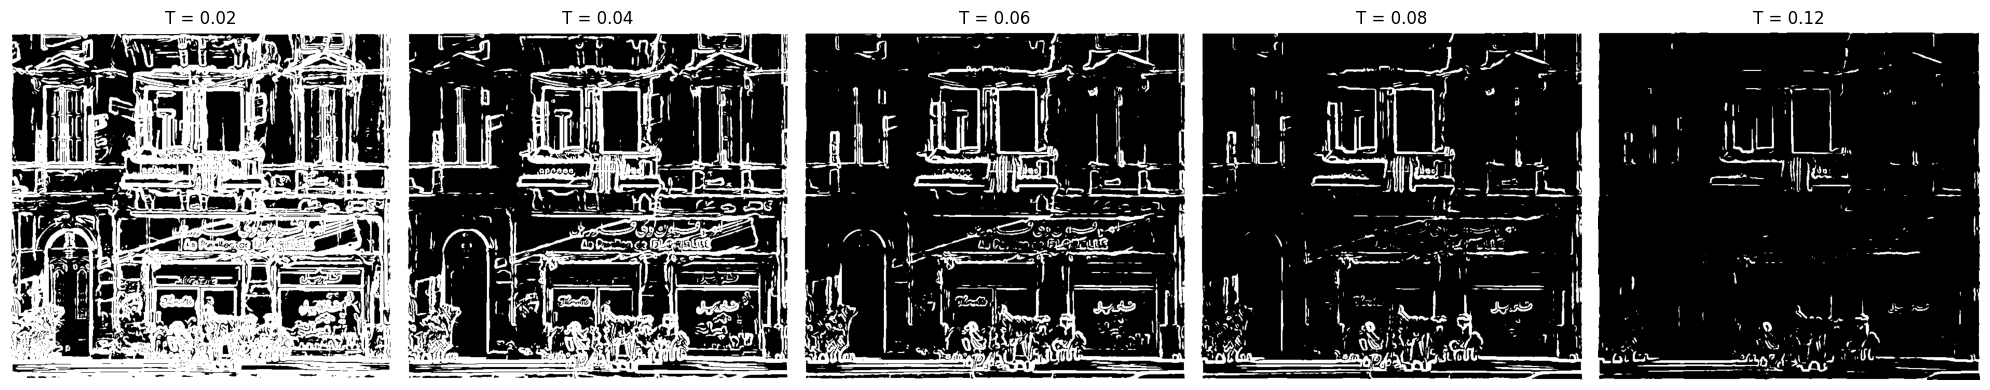

In [14]:
dx_f, dy_f = dog_diff(gray_f, dogx, dogy)
gm_dog_f = gradient_magnitude(dx_f, dy_f)

fig, ax = plt.subplots(1, 5, figsize=(20, 4))
for a, t in zip(ax, [0.02, 0.04, 0.06, 0.08, 0.12]):
    a.imshow(gm_dog_f > t, cmap="gray"); a.set_title(f"T = {t}"); a.axis("off")
plt.tight_layout(); plt.show()

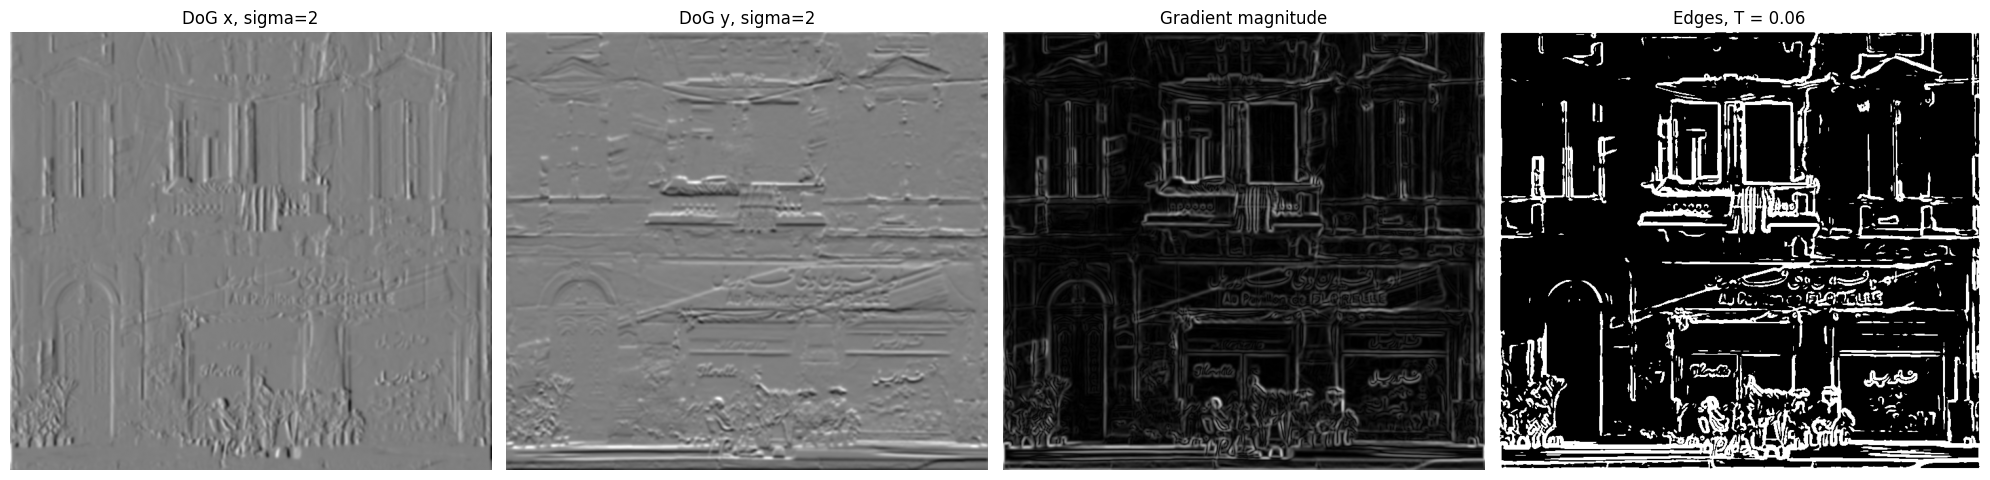

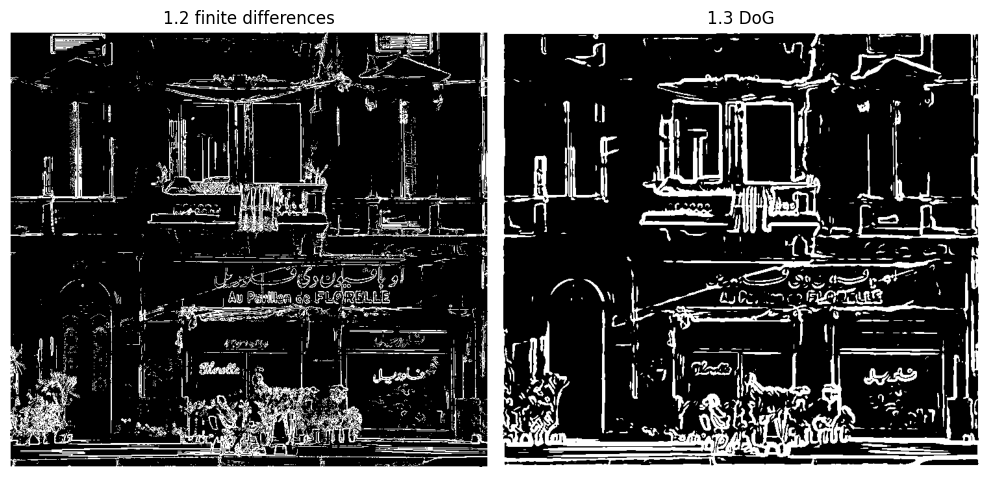

In [15]:
T13_f = 0.06
edges13_f = gm_dog_f > T13_f
row([signed_to_display(dx_f), signed_to_display(dy_f), gm_dog_f / gm_dog_f.max(), edges13_f.astype(float)],
    [f"DoG x, sigma={SIGMA}", f"DoG y, sigma={SIGMA}", "Gradient magnitude", f"Edges, T = {T13_f}"],
    name="1_3_facade", size=5)
row([edges12_f.astype(float), edges13_f.astype(float)], ["1.2 finite differences", "1.3 DoG"],
    name="1_3_facade_compare", size=5)